In [1]:
%pip install -qU langchain langchain-openai langchain-community langgraph langchain-mcp-adapters mcp chromadb tiktoken bs4

Note: you may need to restart the kernel to use updated packages.


In [2]:
# 환경 변수 설정
import os
from dotenv import load_dotenv

load_dotenv()

# OpenAI API 키 설정 (환경 변수에 없으면 직접 입력)
if not os.getenv("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = "your-openai-api-key"

In [3]:
# 문서 로드 및 벡터 스토어 생성
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import Chroma
from langchain_openai import OpenAIEmbeddings

# 임베딩 모델 설정
embeddings = OpenAIEmbeddings()

# PDF 파일 경로 설정 (OpenAI RAG 실습과 동일한 문서 사용)
file_path = "../../docs/DeepSeek_OCR_paper.pdf"

# PDF 로더 초기화 및 문서 로드
loader = PyPDFLoader(file_path)
docs = loader.load()
docs

/var/folders/nb/vk2763xn5fg84sm4wwvmjzm40000gn/T/ipykernel_83676/1093612434.py:3: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


[Document(metadata={'producer': 'pdfTeX-1.40.27', 'creator': 'LaTeX with hyperref', 'creationdate': '2025-10-17T08:28:51+00:00', 'author': '', 'keywords': '', 'moddate': '2025-10-17T08:28:51+00:00', 'ptex.fullbanner': 'This is pdfTeX, Version 3.141592653-2.6-1.40.27 (TeX Live 2025) kpathsea version 6.4.1', 'subject': '', 'title': '', 'trapped': '/False', 'source': '../../docs/DeepSeek_OCR_paper.pdf', 'total_pages': 22, 'page': 0, 'page_label': '1'}, page_content='DeepSeek-OCR: Contexts Optical Compression\nHaoran Wei, Yaofeng Sun, Yukun Li\nDeepSeek-AI\nAbstract\nWe present DeepSeek-OCR as an initial investigation into the feasibility of compressing long\ncontexts via optical 2D mapping. DeepSeek-OCR consists of two components: DeepEncoder\nand DeepSeek3B-MoE-A570M as the decoder. Specifically, DeepEncoder serves as the core\nengine, designed to maintain low activations under high-resolution input while achieving high\ncompression ratios to ensure an optimal and manageable number of vi

In [4]:
print(f"📄 로드된 문서 수: {len(docs)} 페이지")

📄 로드된 문서 수: 22 페이지


In [5]:
# 문서 분할
text_splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(
    chunk_size=1000, 
    chunk_overlap=200
)
doc_splits = text_splitter.split_documents(docs)

print(doc_splits[0].page_content)

DeepSeek-OCR: Contexts Optical Compression
Haoran Wei, Yaofeng Sun, Yukun Li
DeepSeek-AI
Abstract
We present DeepSeek-OCR as an initial investigation into the feasibility of compressing long
contexts via optical 2D mapping. DeepSeek-OCR consists of two components: DeepEncoder
and DeepSeek3B-MoE-A570M as the decoder. Specifically, DeepEncoder serves as the core
engine, designed to maintain low activations under high-resolution input while achieving high
compression ratios to ensure an optimal and manageable number of vision tokens. Experiments
show that when the number of text tokens is within 10 times that of vision tokens (i.e., a
compression ratio < 10×), the model can achieve decoding (OCR) precision of 97%. Even at a
compression ratio of 20×, the OCR accuracy still remains at about 60%. This shows considerable
promise for research areas such as historical long-context compression and memory forgetting
mechanisms in LLMs. Beyond this, DeepSeek-OCR also demonstrates high practical va

In [6]:
# 벡터 스토어 생성
vectorstore = Chroma.from_documents(
    documents=doc_splits,
    collection_name="rag-chroma",
    embedding=embeddings,
)

# 리트리버 생성
retriever = vectorstore.as_retriever(search_kwargs={"k": 3})

In [7]:
retriever.invoke("deepseek ocr")

[Document(metadata={'page': 0, 'moddate': '2025-10-17T08:28:51+00:00', 'subject': '', 'page_label': '1', 'ptex.fullbanner': 'This is pdfTeX, Version 3.141592653-2.6-1.40.27 (TeX Live 2025) kpathsea version 6.4.1', 'source': '../../docs/DeepSeek_OCR_paper.pdf', 'creator': 'LaTeX with hyperref', 'creationdate': '2025-10-17T08:28:51+00:00', 'keywords': '', 'title': '', 'trapped': '/False', 'total_pages': 22, 'author': '', 'producer': 'pdfTeX-1.40.27'}, page_content='DeepSeek-OCR: Contexts Optical Compression\nHaoran Wei, Yaofeng Sun, Yukun Li\nDeepSeek-AI\nAbstract\nWe present DeepSeek-OCR as an initial investigation into the feasibility of compressing long\ncontexts via optical 2D mapping. DeepSeek-OCR consists of two components: DeepEncoder\nand DeepSeek3B-MoE-A570M as the decoder. Specifically, DeepEncoder serves as the core\nengine, designed to maintain low activations under high-resolution input while achieving high\ncompression ratios to ensure an optimal and manageable number of vi

In [8]:
# RAG 체인 설정
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_openai import ChatOpenAI

# LLM 모델 설정
llm = ChatOpenAI(model="gpt-4.1-mini", temperature=0)

# RAG 프롬프트 가져오기

prompt = ChatPromptTemplate.from_messages([
    ("system", """You are an assistant for question-answering tasks. 
    Use the following pieces of retrieved context to answer the question. 
    If you don't know the answer, just say that you don't know. 
     Use three sentences maximum and keep the answer concise. Answer in Korean"""),
    ("human", "Question: {question}\n\nContext: {context}\n\nAnswer:")
])

# 문서 포맷팅 함수
def format_docs(docs):
    return "\n\n".join(doc.page_content for doc in docs)

# RAG 체인 생성
rag_chain = prompt | llm | StrOutputParser()

In [9]:
# LangGraph 상태 정의
from typing import TypedDict, List, Annotated
from langchain_core.documents import Document
import operator

class GraphState(TypedDict):
    """RAG 그래프의 상태를 정의"""
    question: str
    documents: List[Document]
    generation: str

In [10]:
# 그래프 노드 함수 정의
def retrieve(state: GraphState) -> GraphState:
    """문서 검색 노드"""
    print("---RETRIEVE---")
    question = state["question"]
    
    # 리트리버를 사용해 관련 문서 검색
    documents = retriever.invoke(question)
    
    return {"question": question, "documents": documents, "generation": ""}


def generate(state: GraphState) -> GraphState:
    """답변 생성 노드"""
    print("---GENERATE---")
    question = state["question"]
    documents = state["documents"]
    
    # 문서를 텍스트로 포맷팅
    docs_txt = format_docs(documents)
    
    # RAG 체인을 사용해 답변 생성
    generation = rag_chain.invoke({"context": docs_txt, "question": question})
    
    return {"question": question, "documents": documents, "generation": generation}

In [11]:
# LangGraph 그래프 생성 및 컴파일
from langgraph.graph import StateGraph, START, END

# 그래프 생성
workflow = StateGraph(GraphState)

# 노드 추가
workflow.add_node("retrieve", retrieve)
workflow.add_node("generate", generate)

# 엣지 연결(출발지, 도착지)
workflow.add_edge(START, "retrieve")
workflow.add_edge("retrieve", "generate")
workflow.add_edge("generate", END)

# 그래프 컴파일
app = workflow.compile()

print("RAG 그래프가 성공적으로 컴파일되었습니다.")

RAG 그래프가 성공적으로 컴파일되었습니다.


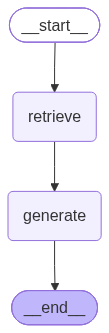

In [12]:
# 그래프 시각화
from IPython.display import Image, display

try:
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception as e:
    print(f"시각화 오류: {e}")
    print("그래프 구조: START -> retrieve -> generate -> END")

In [13]:
# invoke(): 동기 실행 - 전체 결과를 한 번에 반환
# stream(): 스트리밍 실행 - 각 노드 실행 결과를 순차적으로 반환

# RAG 그래프 실행 테스트
question = "Deepseek OCR이 뭐야?"

# 그래프 실행
result = app.invoke({"question": question})

print("=" * 50)
print(f"질문: {result['question']}")
print("=" * 50)
print(f"\n답변:\n{result['generation']}")
print("=" * 50)
print(f"\n참조 문서 수: {len(result['documents'])}")

---RETRIEVE---
---GENERATE---
질문: Deepseek OCR이 뭐야?

답변:
DeepSeek OCR은 고해상도 입력에서 낮은 활성화를 유지하면서 높은 압축률을 달성해 최적의 비전 토큰 수를 관리하는 OCR 모델입니다. 약 100개 언어를 지원하며, 2D 광학 매핑을 통해 긴 문서 컨텍스트를 압축해 높은 정확도의 텍스트 인식을 제공합니다. 또한, 다양한 벤치마크에서 우수한 성능을 보이며 대규모 문서 데이터 생성에도 활용됩니다.

참조 문서 수: 3


In [14]:
# 스트리밍 방식으로 실행
question = "Omnidoc bench 결과는 어때?"

print(f"질문: {question}\n")
print("=" * 50)

for output in app.stream({"question": question}):
    for node_name, value in output.items():
        print(f"\n[{node_name}] 노드 실행 완료")
        if node_name == "generate" and "generation" in value:
            print(f"\n답변:\n{value['generation']}")

질문: Omnidoc bench 결과는 어때?

---RETRIEVE---

[retrieve] 노드 실행 완료
---GENERATE---

[generate] 노드 실행 완료

답변:
Omnidocbench에서 DeepSeek-OCR은 100 비전 토큰만으로 GOT-OCR2.0(256 토큰 사용)을 능가하며, 400 토큰으로는 최첨단 성능과 동등한 결과를 보입니다. 800 토큰 이하(Gundam 모드)에서는 MinerU2.0(약 7,000 토큰 필요)보다 우수한 성능을 나타냅니다. 전반적으로 적은 토큰 수로도 높은 정확도를 달성해 실용적이고 강력한 성능을 입증했습니다.


In [15]:
# PDF 문서 로딩
from langchain_community.document_loaders import PyPDFLoader

pdf_path = "../../docs/DeepSeek_OCR_paper.pdf"

pdf_loader = PyPDFLoader(pdf_path)
docs = [pdf_loader.load()]
print(f"📄 PDF 문서 로드 완료")

📄 PDF 문서 로드 완료


In [16]:
from langchain_core.vectorstores import InMemoryVectorStore

# 문서 분할 및 벡터 스토어 생성
docs_list = [item for sublist in docs for item in sublist]

text_splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(
    chunk_size=1000, chunk_overlap=200
)
doc_splits = text_splitter.split_documents(docs_list)

print(f"✂️ 총 {len(doc_splits)}개의 청크 생성")

# 인메모리 벡터 스토어 생성

vectorstore = InMemoryVectorStore.from_documents(
    documents=doc_splits, 
    embedding=OpenAIEmbeddings()
)
retriever = vectorstore.as_retriever()
print("✅ 문서 벡터 스토어 생성 완료")


✂️ 총 27개의 청크 생성
✅ 문서 벡터 스토어 생성 완료


In [17]:
from langchain.tools import tool

@tool
def retrieve(query: str) -> str:
    """DeepSeek OCR 논문에서 관련 정보를 검색합니다."""
    docs = retriever.invoke(query)
    return "\n\n".join([doc.page_content for doc in docs])

retriever_tool = retrieve
print("✅ Retriever Tool 생성 완료")

✅ Retriever Tool 생성 완료


In [18]:
# 도구 테스트
retriever_tool.invoke({"query": "deepseek ocr 모델"})

'DeepSeek-OCR: Contexts Optical Compression\nHaoran Wei, Yaofeng Sun, Yukun Li\nDeepSeek-AI\nAbstract\nWe present DeepSeek-OCR as an initial investigation into the feasibility of compressing long\ncontexts via optical 2D mapping. DeepSeek-OCR consists of two components: DeepEncoder\nand DeepSeek3B-MoE-A570M as the decoder. Specifically, DeepEncoder serves as the core\nengine, designed to maintain low activations under high-resolution input while achieving high\ncompression ratios to ensure an optimal and manageable number of vision tokens. Experiments\nshow that when the number of text tokens is within 10 times that of vision tokens (i.e., a\ncompression ratio < 10×), the model can achieve decoding (OCR) precision of 97%. Even at a\ncompression ratio of 20×, the OCR accuracy still remains at about 60%. This shows considerable\npromise for research areas such as historical long-context compression and memory forgetting\nmechanisms in LLMs. Beyond this, DeepSeek-OCR also demonstrates hig

In [19]:
from langgraph.graph import MessagesState

response_model = ChatOpenAI(model="gpt-4.1-mini", temperature=0)

def generate_query_or_respond(state: MessagesState):
    """LLM이 검색 여부를 판단하여 tool 호출 또는 직접 응답"""
    response = (
        response_model
        .bind_tools([retriever_tool])
        .invoke(state["messages"])
    )
    return {"messages": [response]}

print("✅ generate_query_or_respond 노드 정의 완료")

✅ generate_query_or_respond 노드 정의 완료


In [20]:
# 테스트: 일반 인사 (검색 불필요)
test_input = {"messages": [{"role": "user", "content": "hello!"}]}
generate_query_or_respond(test_input)["messages"][-1].pretty_print()

================================== Ai Message ==================================

Hello! How can I assist you today?


In [21]:
# 테스트: 검색이 필요한 질문 (Tool Call 발생)
test_input = {"messages": [{"role": "user", "content": "DeepEncoder란?"}]}
generate_query_or_respond(test_input)["messages"][-1].pretty_print()

================================== Ai Message ==================================
Tool Calls:
  retrieve (call_ifbd6P2KNo5jyhuQhjZLHOxZ)
 Call ID: call_ifbd6P2KNo5jyhuQhjZLHOxZ
  Args:
    query: DeepEncoder


In [22]:
from pydantic import BaseModel, Field
from typing import Literal

GRADE_PROMPT = (
    "You are a grader assessing relevance of a retrieved document to a user question.\n"
    "Here is the retrieved document:\n\n{context}\n\n"
    "Here is the user question: {question}\n"
    "If the document contains keyword(s) or semantic meaning related to the user question, grade it as relevant.\n"
    "Give a binary score 'yes' or 'no' to indicate whether the document is relevant."
)

class GradeDocuments(BaseModel):
    """문서 관련성 평가를 위한 이진 점수"""
    binary_score: str = Field(description="Relevance score: 'yes' or 'no'")

grader_model = ChatOpenAI(model="gpt-4.1-mini", temperature=0)

def grade_documents(state: MessagesState) -> Literal["generate_answer", "rewrite_question"]:
    """검색된 문서의 관련성을 평가"""
    question = state["messages"][0].content
    context = state["messages"][-1].content # 사용자의 질문과 가장 연관있는 문서 검색 결과
    
    prompt = GRADE_PROMPT.format(question=question, context=context)
    response = grader_model.with_structured_output(GradeDocuments).invoke(
        [{"role": "user", "content": prompt}]
    )
    
    if response.binary_score == "yes":
        print("---GRADE: 관련 있음---")
        return "generate_answer"
    else:
        print("---GRADE: 관련 없음 → 질문 재작성---")
        return "rewrite_question"

print("✅ grade_documents 조건부 엣지 정의 완료")

✅ grade_documents 조건부 엣지 정의 완료


In [ ]:
from langchain_core.messages import HumanMessage

REWRITE_PROMPT = (
    "Look at the input and try to reason about the underlying semantic intent / meaning.\n"
    "Here is the initial question:\n---\n{question}\n---\n"
    "Formulate an improved question:"
)

def rewrite_question(state: MessagesState):
    """질문을 재작성"""
    print("---REWRITE QUESTION---")
    question = state["messages"][0].content
    prompt = REWRITE_PROMPT.format(question=question)
    response = response_model.invoke([{"role": "user", "content": prompt}])
    return {"messages": [HumanMessage(content=response.content)]}

print("✅ rewrite_question 노드 정의 완료") 

✅ rewrite_question 노드 정의 완료


In [25]:
GENERATE_PROMPT = (
    "You are an assistant for question-answering tasks. "
    "Use the following pieces of retrieved context to answer the question. "
    "If you don't know the answer, just say that you don't know. "
    "Use three sentences maximum and keep the answer concise.\n"
    "Question: {question}\nContext: {context}"
)

def generate_answer(state: MessagesState):
    """최종 답변 생성"""
    print("---GENERATE ANSWER---")
    question = state["messages"][0].content
    context = state["messages"][-1].content
    prompt = GENERATE_PROMPT.format(question=question, context=context)
    response = response_model.invoke([{"role": "user", "content": prompt}])
    return {"messages": [response]}

print("✅ generate_answer 노드 정의 완료")

✅ generate_answer 노드 정의 완료


In [ ]:
from langgraph.prebuilt import ToolNode, tools_condition

# Agentic RAG 그래프 생성
agentic_workflow = StateGraph(MessagesState)

# 노드 추가
agentic_workflow.add_node(generate_query_or_respond)
agentic_workflow.add_node("retrieve", ToolNode([retriever_tool]))
agentic_workflow.add_node(rewrite_question)
agentic_workflow.add_node(generate_answer)

# 시작 엣지
agentic_workflow.add_edge(START, "generate_query_or_respond")

# 조건부 엣지: Tool 호출 여부 판단
agentic_workflow.add_conditional_edges(
    "generate_query_or_respond",
    tools_condition, # Tool 호출 여부 판단
    {"tools": "retrieve", END: END} # Tool 호출 시 "retrieve" 노드로, Tool 호출하지 않으면 END 노드로 이동
)

# 조건부 엣지: 문서 관련성 평가
agentic_workflow.add_conditional_edges("retrieve", grade_documents) # Tool 호출 후 문서 관련성 평가

# 일반 엣지
agentic_workflow.add_edge("generate_answer", END)
agentic_workflow.add_edge("rewrite_question", "generate_query_or_respond")

# 컴파일
agentic_graph = agentic_workflow.compile()
print("✅ Agentic RAG 그래프 컴파일 완료!")


✅ Agentic RAG 그래프 컴파일 완료!


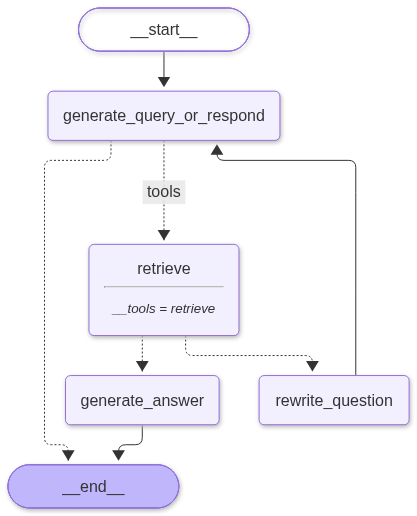

In [27]:
# Agentic RAG 그래프 시각화
try:
    display(Image(agentic_graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print(f"시각화 오류: {e}")